In [1]:
%matplotlib inline
import cv2
import numpy as np
import pathlib
from matplotlib import pyplot as plt
import exiftool
from itertools import count
import ipywidgets as widgets
from IPython.display import display

In [2]:
### Data, paths
PROJ_ROOT = pathlib.Path.cwd().resolve().parent
DATA_RAW = PROJ_ROOT / 'data' / 'raw'
SCALE_FACTOR = 0.25
MAX_CORNER = 100
# ShiTomasi corner detection
config_st = {'maxCorners': MAX_CORNER,
             'qualityLevel': 0.3,
             'minDistance': 7,
             'blockSize': 7}
# Lucas-Kanade optical flow
config_lk = {'winSize': (15, 15),
             'maxLevel': 2,
             'criteria': (cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)}
colors = np.random.randint(0, 255, (100, 3))

In [3]:
from dataclasses import dataclass


@dataclass
class IterationState:
    p_src: np.ndarray
    p_dst: np.ndarray
    R: np.ndarray
    t: np.ndarray
    n: np.ndarray
    

In [21]:


def pre_processing(frame: np.ndarray, scale_factor=SCALE_FACTOR, to_gray=True) -> np.ndarray:
    if to_gray:
        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)  # convert to gray
    frame = cv2.resize(frame, (int(frame.shape[1]*scale_factor), int(frame.shape[0]*scale_factor)), interpolation=cv2.INTER_AREA)# resize
    return frame


def get_intrinsic_matrix(frame: np.ndarray, focal_length: float, diag_35_mm: float = 43.27) -> np.ndarray:
    """
    returns: K - intrinsic camera matrix, 3x3
    """
    # assert len(frame.shape) == 2, 'gray image should be passed'
    f = float(focal_length * np.hypot(*frame.shape[:2]) / diag_35_mm)
    return np.array([
        [f, 0, frame.shape[1] // 2],
        [0, f, frame.shape[0] // 2],
        [0, 0, 1]
    ]).astype(np.float64)


def get_metadata(file_path: str | pathlib.Path ):
    with exiftool.ExifToolHelper() as et:
        return et.get_metadata(str(file_path))[-1]


class FrameViewer:
    """Show frames in one matplotlib figure that updates in place, like cv2.imshow."""

    def __init__(self, title: str = 'lk_track', figsize=(10, 6)):
        self.fig, self.ax = plt.subplots(figsize=figsize)
        self.ax.axis('off')
        self.ax.set_title(title)
        self.artist = None
        self.handle = display(self.fig, display_id=True)
        plt.close(self.fig)  # keep the inline backend from rendering a duplicate copy

    def show(self, frame_bgr: np.ndarray, title: str | None = None) -> None:
        rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        if self.artist is None:
            self.artist = self.ax.imshow(rgb)
        else:
            self.artist.set_data(rgb)  # reuse the existing image instead of redrawing it
        if title:
            self.ax.set_title(title)
        self.handle.update(self.fig)

def update_pose(world_R: np.ndarray, position: np.ndarray, R: np.ndarray, t: np.ndarray,
                step: float = 1.0) -> tuple[np.ndarray, np.ndarray]:
    """Advance the camera by a fixed step along the direction of t.

    Homography decomposition gives X_dst = R @ X_src + t (t scaled by unknown plane distance),
    so only the direction is kept. Camera centre moves by -R.T @ t in the previous camera frame.
    """
    norm = np.linalg.norm(t)
    if norm < 1e-9:
        return world_R, position
    direction_cam = -R.T @ (t.ravel() / norm)
    new_position = position + step * (world_R @ direction_cam)
    return world_R @ R.T, new_position


def draw_path_panel(path: list[np.ndarray], height: int, width: int, margin: int = 20) -> np.ndarray:
    """Top-down (X-Z) view of the accumulated path, auto-scaled to fit the panel."""
    panel = np.zeros((height, width, 3), np.uint8)
    xz = np.array([(p[0], p[2]) for p in path], dtype=np.float64)
    span = np.ptp(xz, axis=0).max() if len(xz) > 1 else 0.0
    scale = (min(height, width) - 2 * margin) / span if span > 0 else 1.0
    centre = (xz.max(axis=0) + xz.min(axis=0)) / 2
    pixels = np.column_stack([width / 2 + (xz[:, 0] - centre[0]) * scale,
                              height / 2 - (xz[:, 1] - centre[1]) * scale]).astype(np.int32)
    cv2.polylines(panel, [pixels.reshape(-1, 1, 2)], False, (0, 255, 255), 2, cv2.LINE_AA)
    cv2.circle(panel, tuple(pixels[0]), 4, (0, 255, 0), -1)
    cv2.circle(panel, tuple(pixels[-1]), 4, (0, 0, 255), -1)
    cv2.putText(panel, f'top view X-Z, steps: {len(path) - 1}', (5, 15),
                cv2.FONT_HERSHEY_PLAIN, 1.0, (200, 200, 200), 1, cv2.LINE_AA)
    return panel


def prepare_visualisation(idx: int, p_src: np.ndarray, p_dst: np.ndarray, target: np.ndarray, mask: np.ndarray,
                          path: list[np.ndarray], arrow_scaler: int = 4) -> np.ndarray:
    """Footage with flow arrows on the left, accumulated path on the right."""
    for _id, (dst, src) in enumerate(zip(p_dst, p_src)):
        color = colors[_id % len(colors)].tolist()
        tip = src + arrow_scaler * (dst - src)
        cv2.arrowedLine(mask, (int(src[0]), int(src[1])), (int(tip[0]), int(tip[1])), color, 2)
        cv2.circle(target, (int(dst[0]), int(dst[1])), 2, color, -1)
    cv2.putText(target, f'frame # {idx}, points found: {len(p_dst)}', (10, target.shape[0] - 10),
                cv2.FONT_HERSHEY_PLAIN, 1.0, (245, 245, 245), thickness=2, lineType=cv2.LINE_AA)
    footage = cv2.add(target, mask)
    panel = draw_path_panel(path, footage.shape[0], footage.shape[0])
    return np.hstack([footage, panel])




Image(value=b'', format='jpeg')

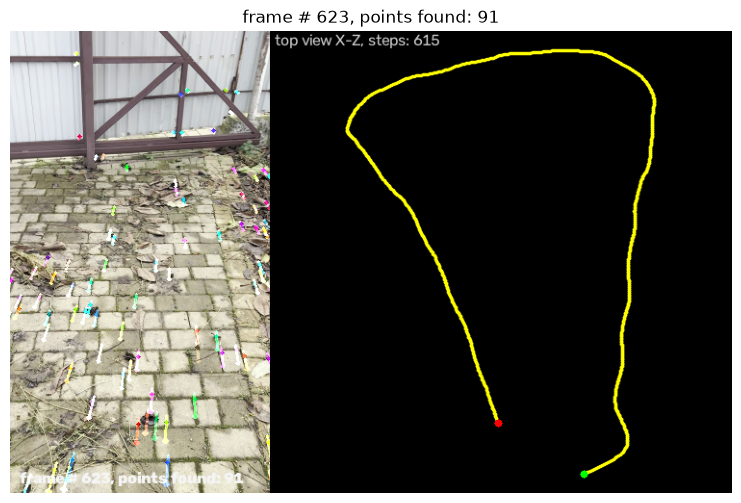

[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low: False
[METRIC] Homography quality: 1.0, is_low

In [26]:
# v1:
# - add tracks
# - jitter compensation

# file_path = DATA_RAW / 'straight_with_yaw.MOV'
# file_path = DATA_RAW / 'straight.MOV'
file_path = DATA_RAW / 'shape.MOV'

video = cv2.VideoCapture(file_path)
_, first_frame = video.read()

previous = pre_processing(first_frame, to_gray=False)
focal_length  = get_metadata(file_path)['QuickTime:FocalLengthIn35mmFormat']
intrinsic = get_intrinsic_matrix(previous, focal_length)


previous_gray = cv2.cvtColor(previous, cv2.COLOR_BGR2GRAY)
p_src = cv2.goodFeaturesToTrack(previous_gray, mask=None, **config_st)

# to draw upon
stop_frame = 100
mask  = np.zeros_like(previous)
counter = count()
view = widgets.Image(format='jpeg')
display(view)
count_per_frame = []
matched_points = []

viewer = FrameViewer('path_tracker')
reference_normal = np.array([0, 0.64, 0.77]) # default normal pointing down
world_R = np.eye(3)
position = np.zeros(3)
path = [position.copy()]


while True:
    idx = next(counter)
    ok, target = video.read()
    if not ok:
        print('end of video')
        break

    target = pre_processing(target, to_gray=False)
    dst_gray = cv2.cvtColor(target, cv2.COLOR_BGR2GRAY)
    p_dst, status, err = cv2.calcOpticalFlowPyrLK(previous_gray, dst_gray, p_src.reshape(-1, 1, 2), None, **config_lk)
    # p_src, status, err = cv2.calcOpticalFlowPyrLK(dst_gray, previous_gray, p_src, None, **config_lk)
    if p_dst is None:
        p_src = cv2.goodFeaturesToTrack(dst_gray, mask=None, **config_st)
        previous_gray = np.copy(dst_gray)
        matched_points.append(None)
        continue

    p_dst = p_dst[status==1]
    p_src = p_src.reshape(-1, 1, 2)[status==1]
    
    if len(p_dst) < 15:
        p_src = cv2.goodFeaturesToTrack(dst_gray, mask=None, **config_st)
        previous_gray = np.copy(dst_gray)
        matched_points.append(None)
        continue

    # stage 3: find Homography
    (H, H_mask) = cv2.findHomography(p_src, p_dst, cv2.RANSAC, 1)
    
    if H is None:
        p_src = cv2.goodFeaturesToTrack(dst_gray, mask=None, **config_st)
        previous_gray = np.copy(dst_gray)
        matched_points.append(None)
        continue

    h_quality_metric = H_mask.sum()/len(H_mask)
    h_quality_is_low = h_quality_metric < 0.5
    print(f'[METRIC] Homography quality: {h_quality_metric}, is_low: {h_quality_is_low}')
    
    if h_quality_is_low:
        p_src = cv2.goodFeaturesToTrack(dst_gray, mask=None, **config_st)
        previous_gray = np.copy(dst_gray)
        matched_points.append(None)
        continue

    num_solutions, R, t, n = cv2.decomposeHomographyMat(H, intrinsic)

    # normalise points:
    p_src_norm = cv2.undistortPoints(p_src.reshape(-1, 1, 2), intrinsic, None)
    p_dst_norm = cv2.undistortPoints(p_dst.reshape(-1, 1, 2), intrinsic, None)

    solutions  = cv2.filterHomographyDecompByVisibleRefpoints(R, n, p_src_norm, p_dst_norm, pointsMask=H_mask)
    if solutions is None or len(solutions) == 0:
        p_src = cv2.goodFeaturesToTrack(dst_gray, mask=None, **config_st)
        previous_gray = np.copy(dst_gray)
        matched_points.append(None)
        continue
    
 

    (winner_id, _) = max([(i, np.dot(reference_normal, n[i].ravel())) for i in solutions], key=lambda x: x[1])
    winner_t =  t[winner_id].ravel()
    winner_n =  n[winner_id].ravel()
    matched_points.append(IterationState(p_src, p_dst, R[winner_id], winner_t,  winner_n))
    if np.linalg.norm(winner_t) > 0.005:  # passes the threshold for movement
        reference_normal =   winner_n

    world_R, position = update_pose(world_R, position, R[winner_id], winner_t)
    path.append(position.copy())

    # drawing tracks:
    # matched_points.append((p_src, p_dst))


    result = prepare_visualisation(idx, p_src, p_dst, target, mask, path)
    viewer.show(result, f'frame # {idx}, points found: {len(p_dst)}')

    #update previous frame and previous points:
    previous_gray = np.copy(dst_gray)
    p_src = p_dst

    # store found points
    count_per_frame.append(len(p_src))
    point_difference = MAX_CORNER - len(p_src)
    if point_difference > 0.1 * MAX_CORNER:
        known_points_mask = np.zeros_like(dst_gray)
        known_points_mask[:] = 255  # fill with white
        for x,y in p_src:
            cv2.circle(known_points_mask, (int(x), int(y)), 7, 0, -1)
        
        # enrich current with new features
        p = cv2.goodFeaturesToTrack(previous_gray, mask=known_points_mask, **{**config_st, 'maxCorners': point_difference})
        if p is not None:
            p_src = np.concatenate([p_src, p.reshape(-1, 2)])
    mask.fill(0)



    # if idx == stop_frame: break



    # select matched points


    